In [58]:
import math
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

batch_size, num_steps = 32, 35
train_iter, vocab = d2l.load_data_time_machine(batch_size, num_steps)

In [59]:


vocab.token_freqs

[(' ', 29927),
 ('e', 17838),
 ('t', 13515),
 ('a', 11704),
 ('i', 10138),
 ('n', 9917),
 ('o', 9758),
 ('s', 8486),
 ('h', 8257),
 ('r', 7674),
 ('d', 6337),
 ('l', 6146),
 ('m', 4043),
 ('u', 3805),
 ('c', 3424),
 ('f', 3354),
 ('w', 3225),
 ('g', 3075),
 ('y', 2679),
 ('p', 2427),
 ('b', 1897),
 ('v', 1295),
 ('k', 1087),
 ('x', 236),
 ('z', 144),
 ('j', 97),
 ('q', 95)]

In [60]:

# vocab.to_tokens
# vocab.idx_to_token
# vocab.token_freqs
# list(vocab.token_to_idx.items())
train_iter.corpus[:100]

[3,
 9,
 2,
 1,
 3,
 5,
 13,
 2,
 1,
 13,
 4,
 15,
 9,
 5,
 6,
 2,
 1,
 21,
 19,
 1,
 9,
 1,
 18,
 1,
 17,
 2,
 12,
 12,
 8,
 5,
 3,
 9,
 2,
 1,
 3,
 5,
 13,
 2,
 1,
 3,
 10,
 4,
 22,
 2,
 12,
 12,
 2,
 10,
 1,
 16,
 7,
 10,
 1,
 8,
 7,
 1,
 5,
 3,
 1,
 17,
 5,
 12,
 12,
 1,
 21,
 2,
 1,
 15,
 7,
 6,
 22,
 2,
 6,
 5,
 2,
 6,
 3,
 1,
 3,
 7,
 1,
 8,
 20,
 2,
 4,
 23,
 1,
 7,
 16,
 1,
 9,
 5,
 13,
 17,
 4,
 8,
 1,
 2,
 24,
 20]

In [61]:
for X, Y in train_iter:
    print(X)
    # print(Y)
    break

tensor([[ 1,  9,  1,  ..., 10,  1,  8],
        [ 1,  3,  9,  ..., 12,  4,  8],
        [ 5,  6, 18,  ..., 11,  1,  9],
        ...,
        [12, 12,  1,  ...,  2,  6,  1],
        [ 2,  1,  3,  ..., 15,  2,  1],
        [ 1,  9,  2,  ..., 11, 10,  2]])


In [62]:
X, Y = next(iter(train_iter))
X



tensor([[ 1, 17,  2,  ...,  1,  5,  3],
        [ 3,  1, 16,  ...,  2,  8,  1],
        [10,  1,  4,  ...,  8,  1,  2],
        ...,
        [ 8,  1,  4,  ...,  3,  1, 21],
        [ 4,  6,  8,  ...,  6, 11,  1],
        [20, 12,  4,  ...,  1, 14, 20]])

In [63]:
len(vocab)

28

In [64]:
X = torch.arange(10).reshape((2, 5))
F.one_hot(X.T, 10).shape

torch.Size([5, 2, 10])

In [65]:
torch.arange(10)

tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [66]:
X = torch.arange(10).reshape((2, 5))
F.one_hot(X.T, 28).shape

torch.Size([5, 2, 28])

In [67]:
def get_params(vocab_size, num_hiddens, device):
    num_inputs = num_outputs = vocab_size

    def normal(shape):
        return torch.randn(size=shape, device=device) * 0.01

    # 隐藏层参数
    W_xh = normal((num_inputs, num_hiddens))
    W_hh = normal((num_hiddens, num_hiddens))
    b_h = torch.zeros(num_hiddens, device=device)
    # 输出层参数
    W_hq = normal((num_hiddens, num_outputs))
    b_q = torch.zeros(num_outputs, device=device)
    # 附加梯度
    params = [W_xh, W_hh, b_h, W_hq, b_q]
    for param in params:
        param.requires_grad_(True)
    return params

In [68]:
#初始化最开始的隐藏状态
def init_rnn_state(batch_size, num_hiddens, device):
    return (torch.zeros((batch_size, num_hiddens), device=device), )

$
H_0 = 0
$

$
H_t = \tanh(X_t W_{xh} + H_{t-1} W_{hh} + b_h)
$

$
Y_t = H_t W_{hq} + b_q
$

$
\hat{y}_t = \mathrm{softmax}(Y_t)
= P(x_{t+1} \mid H_t)
$







$ 
H_1 = \tanh(X_1 W_{xh} + H_0 W_{hh} + b_h)
$

In [69]:
def rnn(inputs, state, params):
    # inputs的形状：(时间步数量，批量大小，词表大小)
    W_xh, W_hh, b_h, W_hq, b_q = params
    H, = state
    outputs = []
    # X的形状：(批量大小，词表大小)
    for X in inputs:
        H = torch.tanh(torch.mm(X, W_xh) + torch.mm(H, W_hh) + b_h)
        Y = torch.mm(H, W_hq) + b_q
        outputs.append(Y)
    return torch.cat(outputs, dim=0), (H,)

In [70]:
class RNNModelScratch: #@save
    """从零开始实现的循环神经网络模型"""
    def __init__(self, vocab_size, num_hiddens, device,
                 get_params, init_state, forward_fn):
        self.vocab_size, self.num_hiddens = vocab_size, num_hiddens
        self.params = get_params(vocab_size, num_hiddens, device)
        self.init_state, self.forward_fn = init_state, forward_fn

    def __call__(self, X, state):
        X = F.one_hot(X.T, self.vocab_size).type(torch.float32)
        return self.forward_fn(X, state, self.params)

    def begin_state(self, batch_size, device):
        return self.init_state(batch_size, self.num_hiddens, device)

In [71]:
num_hiddens = 512

# print(X.to(d2l.try_gpu()))
net = RNNModelScratch(len(vocab), num_hiddens, d2l.try_gpu(), get_params,
                      init_rnn_state, rnn)
state = net.begin_state(X.shape[0], d2l.try_gpu())
Y, new_state = net(X.to(d2l.try_gpu()), state)
Y.shape, len(new_state), new_state[0].shape

(torch.Size([10, 28]), 1, torch.Size([2, 512]))

In [72]:
Y = F.one_hot(X.T, 28)
print(Y.shape)
for y in Y:
    print(y.shape)



torch.Size([5, 2, 28])
torch.Size([2, 28])
torch.Size([2, 28])
torch.Size([2, 28])
torch.Size([2, 28])
torch.Size([2, 28])


In [73]:
def predict_ch8(prefix, num_preds, net, vocab, device):  #@save
    """在prefix后面生成新字符"""
    state = net.begin_state(batch_size=1, device=device)
    outputs = [vocab[prefix[0]]]
    get_input = lambda: torch.tensor([outputs[-1]], device=device).reshape((1, 1))
    for y in prefix[1:]:  # 预热期
        _, state = net(get_input(), state)
        outputs.append(vocab[y])
    for _ in range(num_preds):  # 预测num_preds步
        y, state = net(get_input(), state)
        outputs.append(int(y.argmax(dim=1).reshape(1)))
    return ''.join([vocab.idx_to_token[i] for i in outputs])

In [74]:
predict_ch8('time traveller ', 10, net, vocab, d2l.try_gpu())

'time traveller ph<unk>r ph<unk>r '

In [75]:
out = [vocab[prefix[0]]]
get_input1 = lambda: torch.tensor([out[-1]]).reshape((1, 1))
for y in prefix[1:]:  
    print(get_input1())
    out.append(vocab[y])
    

tensor([[3]])
tensor([[5]])
tensor([[13]])
tensor([[2]])
tensor([[1]])
tensor([[3]])
tensor([[10]])
tensor([[4]])
tensor([[22]])
tensor([[2]])
tensor([[12]])
tensor([[12]])
tensor([[2]])
tensor([[10]])


In [76]:
prefix[0]

't'

In [77]:
vocab['f']

16

In [78]:
# 假装模型输出：1 个样本、词表 5 个字符，分数随便写
y = torch.tensor([[0.1, 2.0, 0.3, 5.0, 0.2]])
print('y.shape', y.shape)
print('y', y)
a = y.argmax(dim=1)
print('argmax', a, 'shape', a.shape)  

y.shape torch.Size([1, 5])
y tensor([[0.1000, 2.0000, 0.3000, 5.0000, 0.2000]])
argmax tensor([3]) shape torch.Size([1])


In [79]:
b = a.reshape(1)
print('reshape', b, 'shape', b.shape)

reshape tensor([3]) shape torch.Size([1])


In [80]:
idx = int(a)
print('int', idx, type(idx)) 

int 3 <class 'int'>


In [81]:
a.reshape(1) 

tensor([3])

In [82]:
#梯度裁剪 （梯度太大时  防止梯度爆炸）
def grad_clipping(net, theta):  #@save
    """裁剪梯度"""
    if isinstance(net, nn.Module):
        params = [p for p in net.parameters() if p.requires_grad]
    else:
        params = net.params
    norm = torch.sqrt(sum(torch.sum((p.grad ** 2)) for p in params))
    if norm > theta:
        for param in params:
            param.grad[:] *= theta / norm

In [83]:
def train_epoch_ch8(net, train_iter, loss, updater, device, use_random_iter):
    """训练网络一个迭代周期（定义见第8章）"""
    state, timer = None, d2l.Timer()
    metric = d2l.Accumulator(2)  # 训练损失之和,词元数量
    for X, Y in train_iter:
        if state is None or use_random_iter:
            # 在第一次迭代或使用随机抽样时初始化state
            state = net.begin_state(batch_size=X.shape[0], device=device)
        else:
            if isinstance(net, nn.Module) and not isinstance(state, tuple):
                # state对于nn.GRU是个张量
                state.detach_() #作用就是在求导过程中 符合函数的链条变短了 
            else:
                # state对于nn.LSTM或对于我们从零开始实现的模型是个张量
                for s in state:
                    s.detach_() #作用就是在求导过程中 符合函数的链条变短了 
        y = Y.T.reshape(-1)
        X, y = X.to(device), y.to(device)
        y_hat, state = net(X, state)
        l = loss(y_hat, y.long()).mean()
        if isinstance(updater, torch.optim.Optimizer):
            updater.zero_grad()
            l.backward()
            grad_clipping(net, 1)
            updater.step()
        else:
            l.backward()
            grad_clipping(net, 1)
            # 因为已经调用了mean函数
            updater(batch_size=1)
        metric.add(l * y.numel(), y.numel())
    return math.exp(metric[0] / metric[1]), metric[1] / timer.stop()

In [84]:
def train_ch8(net, train_iter, vocab, lr, num_epochs, device,
              use_random_iter=False):
    """训练模型（定义见第8章）"""
    loss = nn.CrossEntropyLoss()
    animator = d2l.Animator(xlabel='epoch', ylabel='perplexity',
                            legend=['train'], xlim=[10, num_epochs])
    # 初始化
    if isinstance(net, nn.Module):
        updater = torch.optim.SGD(net.parameters(), lr)
    else:
        updater = lambda batch_size: d2l.sgd(net.params, lr, batch_size)
    predict = lambda prefix: predict_ch8(prefix, 50, net, vocab, device)
    # 训练和预测
    for epoch in range(num_epochs):
        ppl, speed = train_epoch_ch8(
            net, train_iter, loss, updater, device, use_random_iter)
        if (epoch + 1) % 10 == 0:
            print(predict('time traveller'))
            animator.add(epoch + 1, [ppl])
    print(f'困惑度 {ppl:.1f}, {speed:.1f} 词元/秒 {str(device)}')
    print(predict('time traveller'))
    print(predict('traveller'))

困惑度 1.0, 213633.8 词元/秒 cpu
time travelleryou can show black is white by argument said filby
travelleryou can show black is white by argument said filby


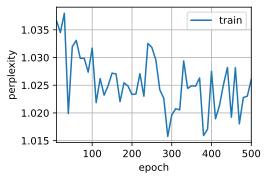

In [86]:
num_epochs, lr = 500, 1
train_ch8(net, train_iter, vocab, lr, num_epochs, d2l.try_gpu())